<a href="https://colab.research.google.com/github/rxphaelbihag/DS171-Intro-to-Supervised-Machine-Learning/blob/main/Logistic_Regression_on_IRIS_Dataset_with_Evaluation_Metrics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratory Exercise 5: Logistic Regression on IRIS Dataset with Evaluation Metrics

Student No.: 2024-05203

Full Name: Raphael Khandie B. Bihag

Section: DS171 (N-1L)

In [1]:
# Importing the libraries
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## Instructions:

*   Read and follow the given instructions.
*   A step-by-step process is given in each cell. Your task is to supply the required tasks.
*   For the synthesis questions, write your answers in the next cell. Your answers should be only 2-3 sentences.



Fetch and load the dataset

In [3]:
dataset =pd.read_csv('/content/iris.csv')
dataset.describe()

,sepal.length,sepal.width,petal.length,petal.width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


Splitting the dataset into the Training set and Test set :

In [4]:
# Splitting the dataset into the Training set and Test set
X = dataset.iloc[:, [0,1,2,3]].values
y = dataset.iloc[:, 4].values
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 0)

Feature Scaling:


In [5]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

Fitting Logistic Regression to the Training set :

In [6]:
# Fitting Logistic Regression to the Training set
from sklearn.linear_model import LogisticRegression
classifier = LogisticRegression(random_state = 0, solver='lbfgs', multi_class='auto')
classifier.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


LogisticRegression(multi_class='auto', random_state=0)

Predicting the Test set results :

In [7]:
# Predicting the Test set results
y_pred = classifier.predict(X_test)
# Predict probabilities
probs_y=classifier.predict_proba(X_test)
### Print results
probs_y = np.round(probs_y, 2)
res = "{:<10} | {:<10} | {:<10} | {:<13} | {:<5}".format("y_test", "y_pred", "Setosa(%)", "versicolor(%)", "virginica(%)\n")
res += "-"*65+"\n"
res += "\n".join("{:<10} | {:<10} | {:<10} | {:<13} | {:<10}".format(x, y, a, b, c) for x, y, a, b, c in zip(y_test, y_pred, probs_y[:,0], probs_y[:,1], probs_y[:,2]))
res += "\n"+"-"*65+"\n"
print(res)

y_test     | y_pred     | Setosa(%)  | versicolor(%) | virginica(%)
-----------------------------------------------------------------
Virginica  | Virginica  | 0.0        | 0.03          | 0.97      
Versicolor | Versicolor | 0.01       | 0.95          | 0.04      
Setosa     | Setosa     | 1.0        | 0.0           | 0.0       
Virginica  | Virginica  | 0.0        | 0.08          | 0.92      
Setosa     | Setosa     | 0.98       | 0.02          | 0.0       
Virginica  | Virginica  | 0.0        | 0.01          | 0.99      
Setosa     | Setosa     | 0.98       | 0.02          | 0.0       
Versicolor | Versicolor | 0.01       | 0.71          | 0.28      
Versicolor | Versicolor | 0.0        | 0.73          | 0.27      
Versicolor | Versicolor | 0.02       | 0.89          | 0.08      
Virginica  | Virginica  | 0.0        | 0.44          | 0.56      
Versicolor | Versicolor | 0.02       | 0.76          | 0.22      
Versicolor | Versicolor | 0.01       | 0.85          | 0.13      
Versicol

## **Your** **Tasks**


1.   Create and plot the Confusion Matrix.
2.   Get the accuracy for test data.
3.   Calculate the evaluation metrics (precision, recall, and F1-score).



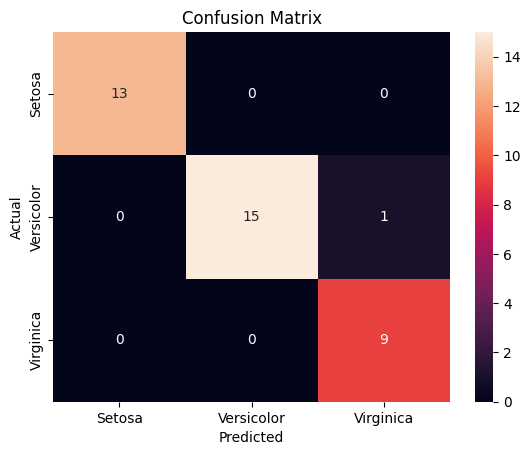

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import metrics

# Confusion Matrix
conf_matrix = metrics.confusion_matrix(y_test, y_pred)

# plot confusion matrix using seaborn's heatmap
classes = classifier.classes_
sns.heatmap(conf_matrix, annot=True, xticklabels=classes, yticklabels=classes)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [17]:
# Accuracy for Test Data
score = classifier.score(X_test, y_test)
print("Model's Score:", score)

Model's Score: 0.9736842105263158


In [25]:
# Calculate Evaluation Metrics
print(metrics.classification_report(y_test, y_pred))

              precision    recall  f1-score   support

      Setosa       1.00      1.00      1.00        13
  Versicolor       1.00      0.94      0.97        16
   Virginica       0.90      1.00      0.95         9

    accuracy                           0.97        38
   macro avg       0.97      0.98      0.97        38
weighted avg       0.98      0.97      0.97        38



### **Analytical Questions**


*   Q1: If the dataset were heavily imbalanced (e.g., 100 Setosa, 45 Versicolor, 5 Virginica), why would high Accuracy be misleading, and how do Macro-averaged Precision, Recall, and F1-Score reveal the model's true performance?

> For an imbalanced dataset, simply using the accuracy would be misleading as it heavily misrepresents an entire class (minority). For example, a model doing excelent on the majority class but bad on the minority class would still give a high accuracy score because the misclassifications in the minority class are not treated of importance. To combat this, metrics such as Macro-averaged Precision, Recall, and F1-Scores are used to expose the performance on every class regardless of class balance. These metrics treats all classes with equal weights, so a poor performance even on a minority class will bring down the score of the model.

*   Q2: Based on your Confusion Matrix, if misclassifying Virginica carries a much higher real-world cost than misclassifying Versicolor, should you optimize for Precision or Recall for Virginica, and why?

$$\text{Precision}=\frac{TP}{TP+FP}$$
$$\text{Recall}=\frac{TP}{TP+FN}$$

> In this situation, we should optimize for Recall because it accounts for the False Negatives. Misclassifying Virginica would be costly in this hypothetical scenario, so we cannot afford to have a Virginica sample unnoticed. By optimizing for recall, we are counting how many Virginicas were misclassified as not, thereby optimizing the cost.


##**Submission**:
Save all your code and analysis answers in a single Jupyter notebook. Make sure that your notebook has the student number, full name, and section commented in the first cell. Export the notebook with complete executed outputs and save it following the filename format “surname_section_labexe5.ipynb”.
- Submit your notebook to the LMS submission bin on or before the specified deadline.
- Late submission will be subject to a point deduction (10% per day, up to a 3-day maximum delay).
- Submissions that do not comply with the stated requirements and guidelines will be graded 0. Refer to the course syllabus for details on the source code evaluation rubric.